# Autoencoder on NF-CICIDS2018, replayed day by day

Same replay as `02_drift_cicids2018.ipynb`, with an anomaly detector instead of the Random Forest.
The autoencoder only learns to reconstruct **benign** traffic; a flow it reconstructs badly is flagged as an
attack. It needs no attack label, so it can in principle flag attack families it has never seen.

Two models are replayed day by day:

- **frozen**: trained on the benign flows of NF-UNSW-NB15 (the training data written by `prepare.py`), deployed
  as is on the NF-CICIDS2018 network and never updated;
- **retrained**: retrained every night on the benign UNSW flows plus the benign flows of all previous CIC days
  (known once the labels of a day arrive, the next day).

The threshold is set so that 1 % of the held-out benign flows of the training data are flagged, and it is
recomputed at each retraining. Same 38 features and same 20 % sample as notebook 02.

In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import yaml
from sklearn.metrics import matthews_corrcoef, roc_auc_score
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data/raw/NF-CICIDS2018-v3.parquet"

with open(ROOT / "params.yaml") as f:
    params = yaml.safe_load(f)
SEED = params["prepare"]["seed"]

with open(ROOT / "data/prepared/feature_columns.json") as f:
    FEATURES = json.load(f)

PERCENT = FuncFormatter(lambda v, _: f"{v:g} %")  # axis ticks as percentages
SAMPLE_FRACTION = 0.20       # same sample as notebook 02
MIN_FLOWS_PER_DAY = 10_000   # 27 Feb only has a few hundred flows
TRAIN_CAP = 200_000          # benign flows used to train the autoencoder
FP_TARGET = 0.01             # share of held-out benign flows above the threshold

print(f"{len(FEATURES)} features")

38 features


## 1. Data

Same loading as notebook 02 (same seed, so the same flows).

In [2]:
t0 = time.perf_counter()
rng = np.random.default_rng(SEED)
parts = []
for batch in pq.ParquetFile(DATA_PATH).iter_batches(batch_size=1_000_000,
                                                    columns=FEATURES + ["FLOW_START_MILLISECONDS", "Label", "Attack"]):
    part = batch.to_pandas()
    parts.append(part[rng.random(len(part)) < SAMPLE_FRACTION])
df = pd.concat(parts, ignore_index=True)
del parts
df[FEATURES] = df[FEATURES].astype("float32")
df["y"] = df["Label"].astype(int)
df["day"] = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms").dt.normalize()

NAMES = {
    "FTP-BruteForce": "FTP brute force", "SSH-Bruteforce": "SSH brute force",
    "DoS_attacks-GoldenEye": "DoS GoldenEye", "DoS_attacks-Slowloris": "DoS Slowloris",
    "DoS_attacks-SlowHTTPTest": "DoS SlowHTTPTest", "DoS_attacks-Hulk": "DoS Hulk",
    "DDoS_attacks-LOIC-HTTP": "DDoS LOIC-HTTP", "DDOS_attack-HOIC": "DDoS HOIC", "DDOS_attack-LOIC-UDP": "DDoS LOIC-UDP",
    "Brute_Force_-Web": "web brute force", "Brute_Force_-XSS": "XSS", "SQL_Injection": "SQL injection",
    "Infilteration": "infiltration", "Bot": "botnet",
}
df["family"] = df["Attack"].map(NAMES).fillna(df["Attack"])
KIND = {"FTP brute force": "brute force", "SSH brute force": "brute force", "web brute force": "web attacks",
        "XSS": "web attacks", "SQL injection": "web attacks", "infiltration": "infiltration", "botnet": "botnet"}
kind = lambda family: KIND.get(family, family.split()[0])  # DoS ..., DDoS ...

counts = df.groupby("day").size()
DAYS = counts.index[counts >= MIN_FLOWS_PER_DAY].tolist()
day_kind = df[df["y"] == 1].groupby("day")["family"].agg(lambda s: " + ".join(sorted({kind(f) for f in s})))
print(f"{len(df):,} flows loaded in {time.perf_counter() - t0:.0f} s, {len(DAYS)} days")

4,021,181 flows loaded in 2 s, 10 days


## 2. The autoencoder

Counts and durations are heavy-tailed, so the features go through `log(1 + x)` and are standardised.
A small network (38 -> 32 -> 8 -> 32 -> 38) learns to output its input. The anomaly score of a flow is
its reconstruction error.

In [3]:
class Autoencoder:
    """Learns to reconstruct benign flows; the anomaly score is the reconstruction error."""

    def __init__(self):
        self.scaler = StandardScaler()
        self.net = MLPRegressor(hidden_layer_sizes=(32, 8, 32), activation="relu", batch_size=512,
                                learning_rate_init=1e-3, max_iter=200, early_stopping=True,
                                n_iter_no_change=5, random_state=SEED)

    def _prepare(self, d):
        x = np.nan_to_num(d[FEATURES].to_numpy(dtype="float64"))  # UNSW rates: inf -> NaN in prepare.py
        return np.log1p(np.clip(x, 0, None))

    def fit(self, benign):
        z = self.scaler.fit_transform(self._prepare(benign))
        self.net.fit(z, z)
        return self

    def score(self, d):
        z = self.scaler.transform(self._prepare(d))
        return ((z - self.net.predict(z)) ** 2).mean(axis=1)


def train(benign):
    """Fit on 80 % of the benign flows; threshold = 99th percentile of the other 20 %."""
    benign = benign.sample(min(TRAIN_CAP, len(benign)), random_state=SEED)
    cut = int(0.8 * len(benign))
    model = Autoencoder().fit(benign.iloc[:cut])
    threshold = np.quantile(model.score(benign.iloc[cut:]), 1 - FP_TARGET)
    return model, threshold, benign.iloc[cut:]


unsw = pd.concat([pd.read_csv(ROOT / f"data/prepared/{name}.csv") for name in ("train", "val")], ignore_index=True)
unsw = unsw.rename(columns={params["prepare"]["target"]: "y"})
unsw_benign = unsw[unsw["y"] == 0]
t0 = time.perf_counter()
frozen, frozen_threshold, _ = train(unsw_benign)
print(f"frozen autoencoder: {min(TRAIN_CAP, len(unsw_benign)):,} benign UNSW flows, "
      f"{frozen.net.n_iter_} epochs, {time.perf_counter() - t0:.0f} s")

frozen autoencoder: 156,210 benign UNSW flows, 40 epochs, 4 s


## 3. Replay

On the first CIC day there is no CIC history yet, so both models are the same.

In [4]:
def rates(y, flagged, score):
    attack, benign = y == 1, y == 0
    return {
        "recall": flagged[attack].mean() if attack.any() else np.nan,
        "false_positive_%": 100 * flagged[benign].mean(),
        "flagged_%": 100 * flagged.mean(),
        "mcc": matthews_corrcoef(y, flagged) if attack.any() and benign.any() else np.nan,
        "auc": roc_auc_score(y, score) if attack.any() else np.nan,
    }


results, families = [], []
for i, day in enumerate(DAYS):
    d = df[df["day"] == day]
    y = d["y"].to_numpy()
    score_frozen = frozen.score(d)
    model, threshold = frozen, frozen_threshold
    if i > 0:
        history = pd.concat([unsw_benign[FEATURES], df.loc[df["day"].isin(DAYS[:i]) & (df["y"] == 0), FEATURES]],
                            ignore_index=True)
        model, threshold, _ = train(history)
    score_retrained = model.score(d)
    flag_frozen, flag_retrained = score_frozen > frozen_threshold, score_retrained > threshold

    row = {"day": day, "flows": len(d), "attack_%": 100 * y.mean()}
    row.update({f"frozen_{k}": v for k, v in rates(y, flag_frozen, score_frozen).items()})
    row.update({f"retrained_{k}": v for k, v in rates(y, flag_retrained, score_retrained).items()})
    results.append(row)

    attacks = d.assign(frozen=flag_frozen, retrained=flag_retrained)[y == 1]
    for family, g in attacks.groupby("family"):
        families.append({"day": day, "family": family, "flows": len(g),
                         "recall_frozen": g["frozen"].mean(), "recall_retrained": g["retrained"].mean()})
    print(f"{day:%d %b} done", flush=True)

results = pd.DataFrame(results)
families = pd.DataFrame(families)
results.assign(day=results["day"].dt.strftime("%d %b")).round(4)

14 Feb done


15 Feb done


16 Feb done


20 Feb done


21 Feb done


22 Feb done


23 Feb done


28 Feb done


01 Mar done


02 Mar done


,day,flows,attack_%,frozen_recall,frozen_false_positive_%,frozen_flagged_%,frozen_mcc,frozen_auc,retrained_recall,retrained_false_positive_%,retrained_flagged_%,retrained_mcc,retrained_auc
0,14 Feb,427661,26.8954,1.0000,89.9159,92.6280,0.1711,0.4996,1.0000,89.9159,92.6280,0.1711,0.4996
1,15 Feb,333605,5.8279,1.0000,89.0487,89.6869,0.0844,0.7483,0.5157,1.3207,4.2490,0.5836,0.9830
2,16 Feb,356431,11.4482,1.0000,89.8766,91.0350,0.1128,0.4551,0.3428,1.0861,4.8862,0.4903,0.9869
3,20 Feb,365634,15.8363,1.0000,90.8111,92.2663,0.1256,0.8783,0.8592,1.5575,14.9176,0.8645,0.9866
4,21 Feb,543396,38.1230,1.0000,90.7892,94.3007,0.1930,0.6599,0.1187,1.2696,5.3116,0.2296,0.9159
5,22 Feb,407768,0.1177,1.0000,91.2170,91.2274,0.0106,0.7483,0.4271,0.7582,0.8076,0.1607,0.9596
6,23 Feb,386251,0.0000,NaN,90.6323,90.6323,NaN,NaN,NaN,0.7889,0.7889,NaN,NaN
7,28 Feb,405310,4.1435,0.8625,92.5511,92.2899,-0.0471,0.4102,0.0297,0.7421,0.8344,0.0488,0.5003
8,01 Mar,428618,4.7588,0.8865,91.7344,91.5876,-0.0237,0.4201,0.0189,2.3191,2.2986,-0.0061,0.5846
9,02 Mar,366358,11.3466,1.0000,91.3079,92.2941,0.1034,0.4666,0.0013,0.8378,0.7575,-0.0259,0.8854


## 4. Detection per day

The main metric is the **MCC** (Matthews correlation coefficient). It uses the four cells of the confusion matrix:
1 = perfect, 0 = no better than chance, negative = worse. Unlike F1 it also counts the benign flows correctly let
through, and unlike accuracy it is not inflated by the large share of benign flows, so it punishes missed attacks
and false alarms alike. It depends on the share of attacks of the day (0.1 % to 38 % here): it compares two models
on the same day better than two days with each other. It is undefined on 23 Feb (no attack).
Recall and false positive rate explain the MCC. The AUC (in the table above) measures how well the
score ranks attacks above benign flows whatever the threshold; an IDS works at a low false positive rate, so
the MCC at the threshold is what matters.

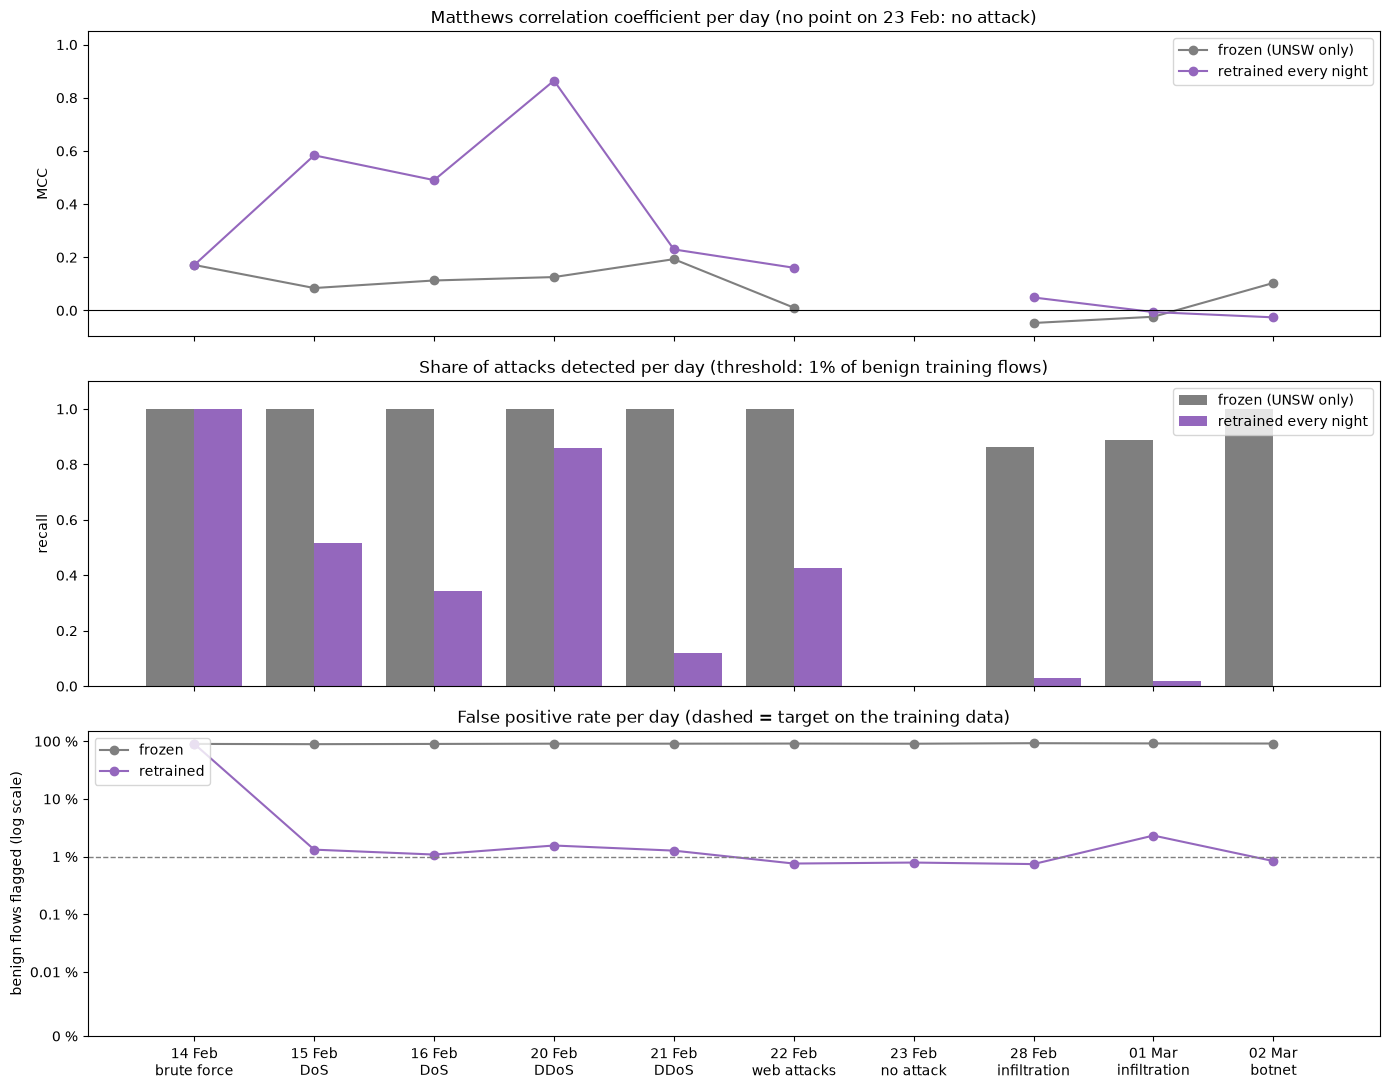

In [5]:
labels = [f"{d:%d %b}\n{day_kind.get(d, 'no attack')}" for d in results["day"]]
x = np.arange(len(results))

fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
mcc_cols = ["frozen_mcc", "retrained_mcc"]
ax0.plot(x, results["frozen_mcc"], "o-", color="tab:grey", label="frozen (UNSW only)")
ax0.plot(x, results["retrained_mcc"], "o-", color="tab:purple", label="retrained every night")
ax0.axhline(0, color="black", lw=0.8)
ax0.set_ylim(min(0, results[mcc_cols].min().min()) - 0.05, 1.05)
ax0.set_ylabel("MCC")
ax0.set_title("Matthews correlation coefficient per day (no point on 23 Feb: no attack)")
ax0.legend(loc="upper right")
ax1.bar(x - 0.2, results["frozen_recall"], 0.4, label="frozen (UNSW only)", color="tab:grey")
ax1.bar(x + 0.2, results["retrained_recall"], 0.4, label="retrained every night", color="tab:purple")
ax1.set_ylim(0, 1.1)
ax1.set_ylabel("recall")
ax1.set_title(f"Share of attacks detected per day (threshold: {FP_TARGET:.0%} of benign training flows)")
ax1.legend(loc="upper right")

ax2.plot(x, results["frozen_false_positive_%"], "o-", color="tab:grey", label="frozen")
ax2.plot(x, results["retrained_false_positive_%"], "o-", color="tab:purple", label="retrained")
ax2.axhline(100 * FP_TARGET, ls="--", color="grey", lw=1)
ax2.set_yscale("symlog", linthresh=0.01)
ax2.set_ylim(0, 150)
ax2.yaxis.set_major_formatter(PERCENT)
ax2.set_ylabel("benign flows flagged (log scale)")
ax2.set_title("False positive rate per day (dashed = target on the training data)")
ax2.set_xticks(x, labels)
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [6]:
# Recall per attack family
families.assign(day=families["day"].dt.strftime("%d %b")).round(3)

,day,family,flows,recall_frozen,recall_retrained
0,14 Feb,FTP brute force,77300,1.000,1.000
1,14 Feb,SSH brute force,37721,1.000,1.000
2,15 Feb,DoS GoldenEye,12209,1.000,0.310
3,15 Feb,DoS Slowloris,7233,1.000,0.862
4,16 Feb,DoS Hulk,19898,1.000,0.703
5,16 Feb,DoS SlowHTTPTest,20907,1.000,0.000
6,20 Feb,DDoS LOIC-HTTP,57903,1.000,0.859
7,21 Feb,DDoS HOIC,206489,1.000,0.116
8,21 Feb,DDoS LOIC-UDP,670,1.000,1.000
9,22 Feb,SQL injection,80,1.000,0.862


## 5. Drift signal without labels

The share of flows above the threshold is known right away. On benign traffic like the training data it
should stay close to 1 %: more means that something new is in the traffic (new attacks, or benign traffic that
changed). Here a drift alert is raised when it exceeds twice the target. 23 Feb has no attack.

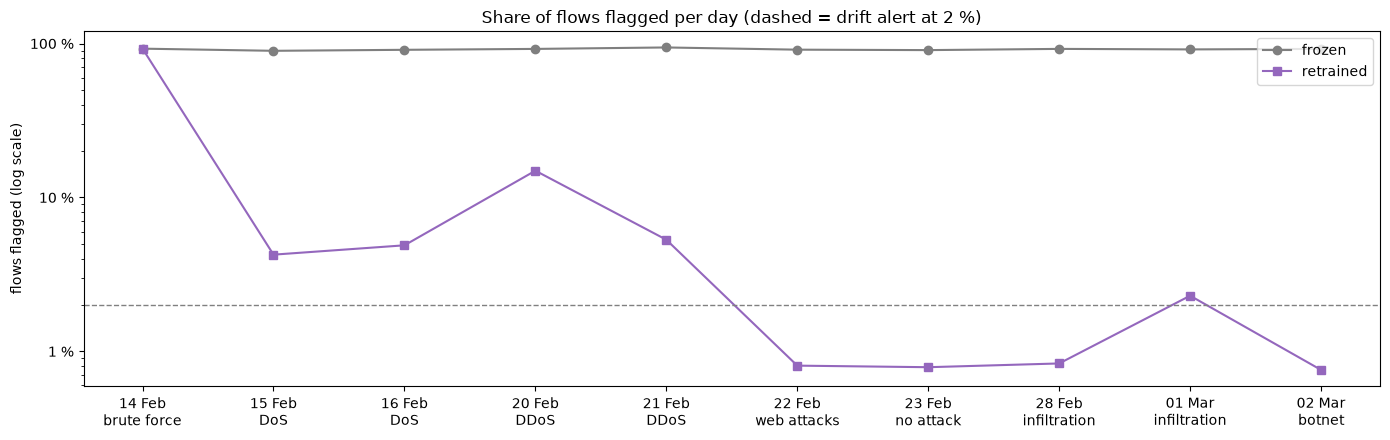

,day,new_family,frozen_flagged_%,frozen_alert,retrained_flagged_%,retrained_alert
0,14 Feb,True,92.63,True,92.63,True
1,15 Feb,True,89.69,True,4.25,True
2,16 Feb,True,91.04,True,4.89,True
3,20 Feb,True,92.27,True,14.92,True
4,21 Feb,True,94.30,True,5.31,True
5,22 Feb,True,91.23,True,0.81,False
6,23 Feb,False,90.63,True,0.79,False
7,28 Feb,True,92.29,True,0.83,False
8,01 Mar,False,91.59,True,2.30,True
9,02 Mar,True,92.29,True,0.76,False


In [7]:
ALERT = 2 * 100 * FP_TARGET
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(x, results["frozen_flagged_%"], "o-", color="tab:grey", label="frozen")
ax.plot(x, results["retrained_flagged_%"], "s-", color="tab:purple", label="retrained")
ax.axhline(ALERT, ls="--", color="grey", lw=1)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(PERCENT)
ax.set_ylabel("flows flagged (log scale)")
ax.set_title(f"Share of flows flagged per day (dashed = drift alert at {ALERT:.0f} %)")
ax.set_xticks(x, labels)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

new_family = [bool(set(df.loc[(df["day"] == d) & (df["y"] == 1), "family"])
                   - set(df.loc[df["day"].isin(DAYS[:i]) & (df["y"] == 1), "family"])) for i, d in enumerate(DAYS)]
pd.DataFrame({"day": results["day"].dt.strftime("%d %b"), "new_family": new_family,
              "frozen_flagged_%": results["frozen_flagged_%"], "frozen_alert": results["frozen_flagged_%"] > ALERT,
              "retrained_flagged_%": results["retrained_flagged_%"], "retrained_alert": results["retrained_flagged_%"] > ALERT}).round(2)

## 6. Compared with the Random Forest (notebook 02)

Run `02_drift_cicids2018.ipynb` first: it writes `drift_cicids2018_days.csv`.

In [8]:
rf = pd.read_csv(ROOT / "notebooks/drift_cicids2018_days.csv", parse_dates=["day"])
comparison = pd.DataFrame({
    "day": results["day"].dt.strftime("%d %b"),
    "attacks": [day_kind.get(d, "no attack") for d in results["day"]],
    "RF frozen MCC": rf["frozen_mcc"].to_numpy(),
    "AE frozen MCC": results["frozen_mcc"].to_numpy(),
    "RF retrained MCC": rf["retrained_mcc"].to_numpy(),
    "AE retrained MCC": results["retrained_mcc"].to_numpy(),
    "RF retrained recall": rf["retrained_recall"].to_numpy(),
    "AE retrained recall": results["retrained_recall"].to_numpy(),
    "RF retrained FP %": rf["retrained_false_positive_%"].to_numpy(),
    "AE retrained FP %": results["retrained_false_positive_%"].to_numpy(),
})
comparison.round(3)

,day,attacks,RF frozen MCC,AE frozen MCC,RF retrained MCC,AE retrained MCC,RF retrained recall,AE retrained recall,RF retrained FP %,AE retrained FP %
0,14 Feb,brute force,0.045,0.171,0.045,0.171,0.672,1.000,62.291,89.916
1,15 Feb,DoS,-0.177,0.084,-0.000,0.584,0.000,0.516,0.000,1.321
2,16 Feb,DoS,-0.054,0.113,0.749,0.490,0.590,0.343,0.002,1.086
3,20 Feb,DDoS,0.272,0.126,0.013,0.865,0.001,0.859,0.013,1.558
4,21 Feb,DDoS,0.406,0.193,0.041,0.230,0.003,0.119,0.014,1.270
5,22 Feb,web attacks,0.022,0.011,-0.000,0.161,0.000,0.427,0.001,0.758
6,23 Feb,no attack,NaN,NaN,NaN,NaN,NaN,NaN,0.010,0.789
7,28 Feb,infiltration,-0.103,-0.047,-0.003,0.049,0.000,0.030,0.047,0.742
8,01 Mar,infiltration,-0.050,-0.024,0.588,-0.006,0.373,0.019,0.082,2.319
9,02 Mar,botnet,0.218,0.103,-0.011,-0.026,0.000,0.001,0.101,0.838


In [9]:
# Per-day results, used for the slides
results.assign(day=results["day"].dt.strftime("%Y-%m-%d"),
               attacks=[day_kind.get(d, "no attack") for d in results["day"]]
               ).to_csv(ROOT / "notebooks/autoencoder_cicids2018_days.csv", index=False)
print("saved notebooks/autoencoder_cicids2018_days.csv")

saved notebooks/autoencoder_cicids2018_days.csv


## What this shows

- Trained on benign UNSW traffic, the autoencoder flags about 90 % of the benign CIC flows (MCC 0.19 at best): for
  it, the whole new network is an anomaly.
- Retrained every night on benign UNSW plus the benign flows of the previous CIC days, it flags about 1 % of the
  benign flows (0.7 % to 2.3 %) and, without any attack label, reaches an MCC of 0.58 (15 Feb, DoS), 0.49 (16 Feb,
  DoS), 0.86 (20 Feb, DDoS LOIC-HTTP), 0.23 (21 Feb, DDoS) and 0.16 (22 Feb, web attacks) on the day these families
  appear. On the same days the retrained Random Forest of notebook 02 is close to 0, except on 16 Feb (0.75).
- Recall per family: DDoS LOIC-HTTP 86 %, DoS Slowloris 86 %, XSS 92 %, SQL injection 86 %, DoS Hulk 70 %, DDoS
  LOIC-UDP 100 %, DoS GoldenEye 31 %, DDoS HOIC 12 %.
- It stays blind to DoS SlowHTTPTest, web brute force, infiltration (AUC about 0.5: these flows look like benign
  traffic) and botnet: MCC about 0 on 28 Feb, 1 Mar and 2 Mar.
- The cost: about 1 % of the benign flows flagged every day, against 0.0003 % to 0.1 % for the retrained Random
  Forest. Results close to the threshold also change with the training sample.
- As a drift signal without labels (share of flagged flows above 2 %), the retrained autoencoder fires on 15, 16, 20
  and 21 Feb and stays quiet on the control day (23 Feb), but misses 22 and 28 Feb and 2 Mar, and fires on 1 Mar when
  only the benign traffic changed.

So the two models complement each other: the Random Forest is best when an attack was already seen (16 Feb, 1 Mar)
and raises almost no false alarm; the autoencoder catches part of the new families on the day they appear (15, 20,
21 and 22 Feb), at the cost of about 1 % false alarms.